In [82]:
from core.config import DB_PATH
from matplotlib import pyplot as plt
import pandas as pd
import sqlite3 as sql

plt.rcParams["figure.figsize"]=(12.8, 7.2)

In [59]:
with sql.connect(DB_PATH) as conn:
    df = pd.read_sql("SELECT * FROM pokemons", conn)
    species = pd.read_sql("SELECT * FROM species", conn)

In [60]:
df = df.iloc[:, :-1]
df["base_experience"] = df["base_experience"].astype("Int64")
species = species.set_index("id")

In [61]:
df

,id,name,height,weight,hp,attack,defense,special_attack,special_defense,speed,total_stats,base_experience,types,primary_type,abilities,hidden_abilities,is_default,species_id
0,1,bulbasaur,70,6.9,45,49,49,65,65,45,318,64,"grass, poison",grass,overgrow,chlorophyll,1,1
1,2,ivysaur,100,13.0,60,62,63,80,80,60,405,142,"grass, poison",grass,overgrow,chlorophyll,1,2
2,3,venusaur,200,100.0,80,82,83,100,100,80,525,236,"grass, poison",grass,overgrow,chlorophyll,1,3
3,4,charmander,60,8.5,39,52,43,60,50,65,309,62,fire,fire,blaze,solar-power,1,4
4,5,charmeleon,110,19.0,58,64,58,80,65,80,405,142,fire,fire,blaze,solar-power,1,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1346,10322,tatsugiri-curly-mega,60,24.0,68,65,90,135,125,92,575,<NA>,"dragon, water",dragon,,NaN,0,978
1347,10323,tatsugiri-droopy-mega,60,24.0,68,65,90,135,125,92,575,<NA>,"dragon, water",dragon,,NaN,0,978
1348,10324,tatsugiri-stretchy-mega,60,24.0,68,65,90,135,125,92,575,<NA>,"dragon, water",dragon,,NaN,0,978
1349,10325,baxcalibur-mega,210,315.0,115,175,117,105,101,87,700,<NA>,"dragon, ice",dragon,thermal-exchange,NaN,0,998


In [31]:
species

,name,gender_rate,capture_rate,base_happiness,is_baby,is_legendary,is_mythical,generation
id,,,,,,,,
1,bulbasaur,1,45,70,0,0,0,1
2,ivysaur,1,45,70,0,0,0,1
3,venusaur,1,45,70,0,0,0,1
4,charmander,1,45,70,0,0,0,1
5,charmeleon,1,45,70,0,0,0,1
...,...,...,...,...,...,...,...,...
1021,raging-bolt,-1,10,0,0,0,0,9
1022,iron-boulder,-1,10,0,0,0,0,9
1023,iron-crown,-1,10,0,0,0,0,9


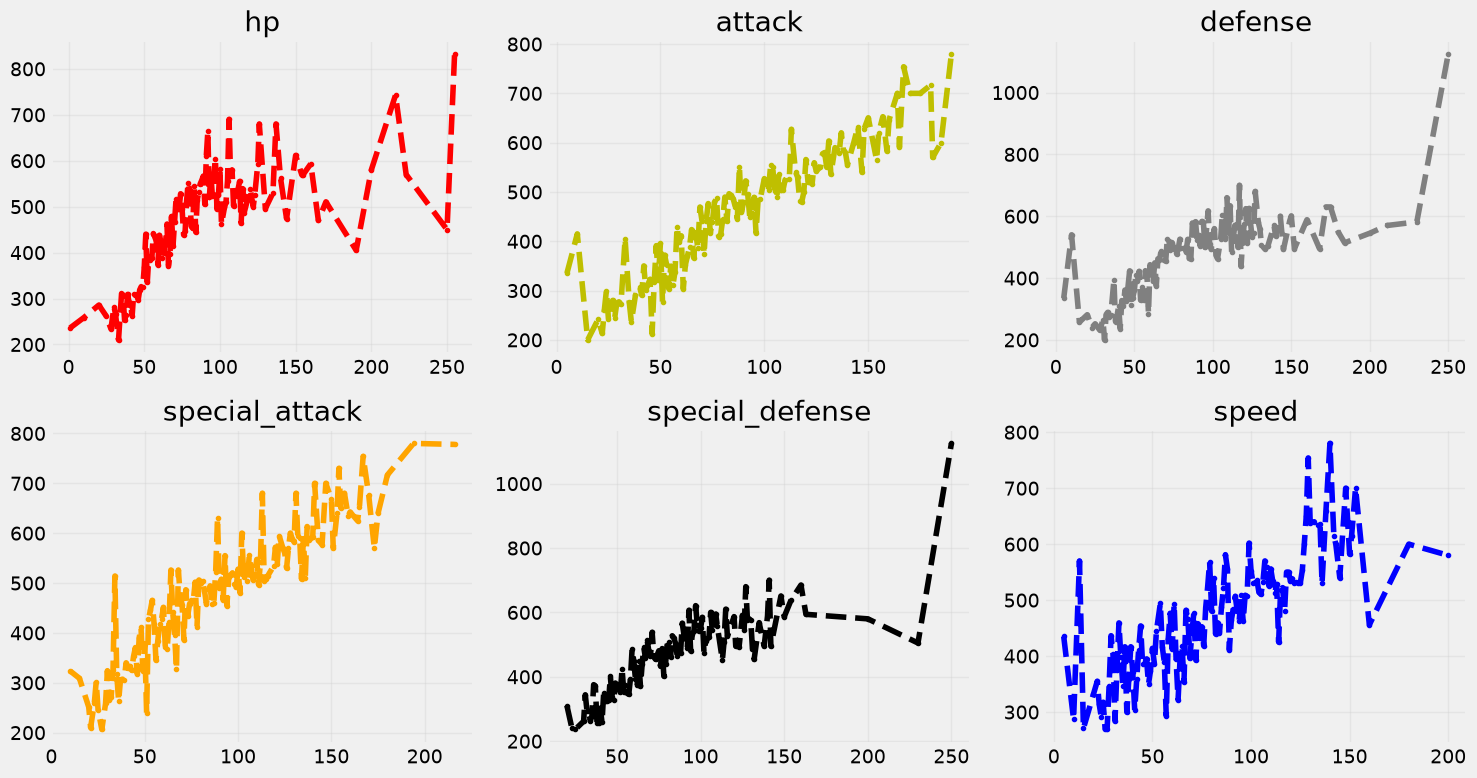

In [116]:
stats = ["hp", "attack", "defense", "special_attack", "special_defense", "speed", "total_stats"]
colors = ["r", "y", "grey", "orange", "k", "b"]
plot_data = df[stats].dropna()
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for ax, stat, color in zip(axes, stats, colors):
    grouped = plot_data.groupby(stat, as_index=False)["total_stats"].mean()
    ax.plot(grouped[stat], grouped["total_stats"],
            linestyle='--', marker='.', color=color)
    ax.set_title(stat)
    ax.grid(True, alpha=0.3)

plt.style.use("fivethirtyeight")
plt.tight_layout()
plt.show()

findfont: Font family 'xkcd' not found.
findfont: Font family 'xkcd Script' not found.
findfont: Font family 'Comic Neue' not found.
findfont: Font family 'xkcd' not found.
findfont: Font family 'xkcd Script' not found.
findfont: Font family 'Comic Neue' not found.
findfont: Font family 'xkcd' not found.
findfont: Font family 'xkcd Script' not found.
findfont: Font family 'Comic Neue' not found.
findfont: Font family 'xkcd' not found.
findfont: Font family 'xkcd Script' not found.
findfont: Font family 'Comic Neue' not found.
findfont: Font family 'xkcd' not found.
findfont: Font family 'xkcd Script' not found.
findfont: Font family 'Comic Neue' not found.
findfont: Font family 'xkcd' not found.
findfont: Font family 'xkcd Script' not found.
findfont: Font family 'Comic Neue' not found.
findfont: Font family 'xkcd' not found.
findfont: Font family 'xkcd Script' not found.
findfont: Font family 'Comic Neue' not found.
findfont: Font family 'xkcd' not found.
findfont: Font family 'xkcd S

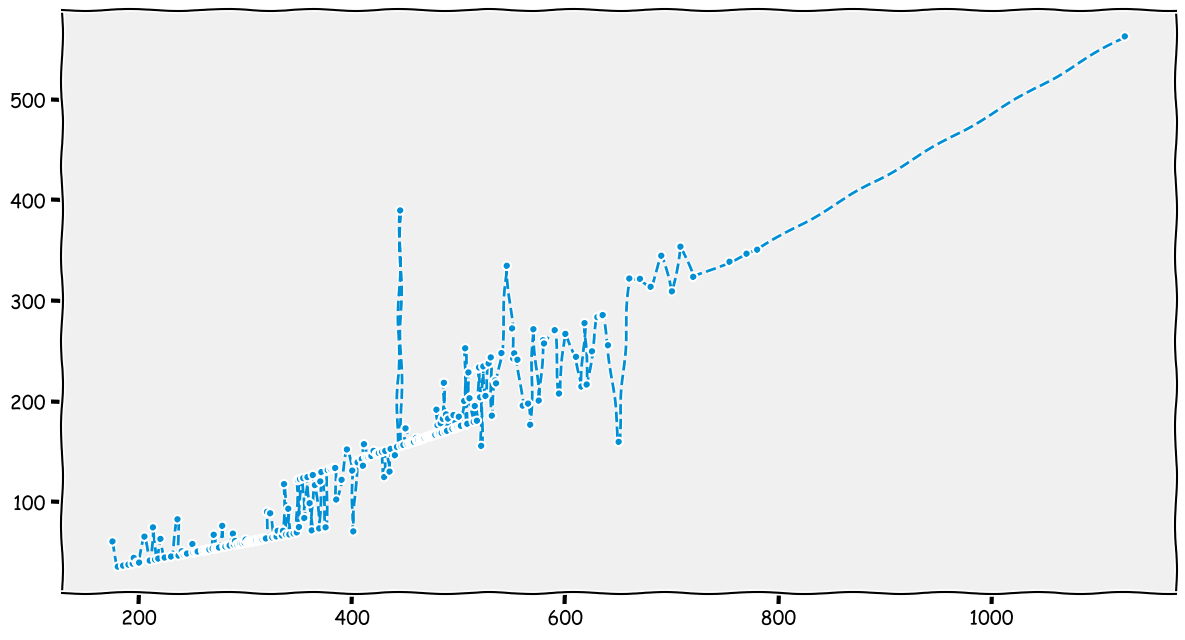

In [118]:
plot_data = df[["total_stats", "base_experience"]]
plot_data = plot_data.dropna()
plot_data = plot_data.sort_values(by=["total_stats"])
plot_data = plot_data.groupby("total_stats", as_index=False).mean()
x = plot_data["total_stats"]
y = plot_data["base_experience"]
plt.xkcd()
plt.plot(x, y, linestyle='--', marker='.')

In [94]:
df[["hp", "base_experience"]]

,base_experience
hp,
1,83.0
10,51.666667
20,69.833333
25,52.25
28,47.0
...,...
200,290.0
216,354.0
223,257.0
